# Task 3 EDA

สำรวจข้อมูลงาน 3: ทำนายยอดใช้จ่ายใน 30 วันข้างหน้า (`spending_30d`, หน่วยบาท)

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from pathlib import Path
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `baseline/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA  # ../cpe342-kaggle-main, needs ROOT on sys.path
print(f"repo root: {ROOT}")

repo root: C:\Users\Admin\Desktop\player-intelligence-system-cpe342


## Load data & fact check

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '03_regression' / 'train.csv') # train
y = tr['spending_30d'] # target

In [4]:
print(f"zero share {round((y == 0).mean(), 3)} | skew {round(y.skew(), 2)} | log1p skew {round(np.log1p(y).skew(), 2)}")

big = y > 20000
print(f"> 20k: {round(big.mean(), 3)} of rows, {round(y[big].sum() / y.sum(), 3)} of spend")
print(tr.groupby('segment', dropna=False)['spending_30d'].apply(lambda s: round((s == 0).mean(), 3)))  # keep NaN segment (5.7% of rows)

zero share 0.481 | skew 4.17 | log1p skew 0.31
> 20k: 0.124 of rows, 0.914 of spend
segment
0.0    0.724
1.0    0.480
2.0    0.306
3.0    0.071
NaN    0.468
Name: spending_30d, dtype: float64


## Where the baseline makes its error

ดูว่า error ของ baseline มาจากช่วงยอดใช้จ่ายไหนมากที่สุด

In [5]:
o = pd.read_csv('baseline/task3_oof.csv') # baseline's out-of-fold predictions
o['err'] = (o['target'] - o['prediction']).abs()
bins, names = [-1, 0, 1000, 20000, 1e9], ['0', '>0-1k', '1k-20k', '>20k']  # '>0-1k' also holds 25 targets below 1 THB
o['bucket'] = pd.cut(o['target'], bins, labels=names)

summary = o.groupby('bucket', observed=True)['err'].agg(['count', 'sum'])
summary['share_of_error'] = (summary['sum'] / summary['sum'].sum()).round(3)
summary

,count,sum,share_of_error
bucket,,,
0,50049,9.117431e+07,0.288
>0-1k,16620,4.896170e+06,0.015
1k-20k,24478,2.050960e+07,0.065
>20k,12853,1.997970e+08,0.632


### Too low or too high?

แยก error ตามทิศ: ทายต่ำกว่าจริง (`error_too_low`) หรือสูงกว่าจริง (`error_too_high`) และดูว่ากี่ % ของแถวที่ทายต่ำไป (`share_under`)

- **>20k:** แถวทั่วไปทายต่ำไปนิดเดียว (median ทาย 63k vs จริง 65k, ทายต่ำแค่ 55% ของแถว) แต่ตอนพลาดหนัก ส่วนใหญ่เป็นการทายต่ำ: error ทายต่ำ 147M vs ทายสูง 53M
- **target = 0:** error 91M ทั้งหมดมาจากทายว่าจะใช้เงิน ทั้งที่ไม่ใช้
- **>0-1k:** ทาย 0 เกือบทุกคน (ทายต่ำ 96% ของแถว) แต่ยอดน้อย error รวมจึงแค่ประมาณ 5M

In [6]:
o['signed'] = o['prediction'] - o['target']  # negative = predicted too low
bias = o.groupby('bucket', observed=True).agg(
    median_target=('target', 'median'),
    median_pred=('prediction', 'median'),
    share_under=('signed', lambda s: (s < 0).mean()),
    error_too_low=('signed', lambda s: (-s).clip(lower=0).sum()),
    error_too_high=('signed', lambda s: s.clip(lower=0).sum()),
)

(bias.style
    .format({'median_target': '{:,.0f}', 'median_pred': '{:,.0f}', 'share_under': '{:.0%}',
             'error_too_low': '{:,.0f}', 'error_too_high': '{:,.0f}'})
    .set_caption('Baseline error by direction, per spend bucket (THB)'))

,median_target,median_pred,share_under,error_too_low,error_too_high
bucket,,,,,
0,0,0,0%,0,"91,174,305"
>0-1k,296,0,96%,"4,610,131","286,039"
1k-20k,"2,606","2,269",76%,"14,952,099","5,557,499"
>20k,"65,196","63,074",55%,"146,953,189","52,843,773"


## Train vs test

เช็กว่ามีแถวซ้ำไหม มี `player_id` ที่อยู่ทั้งสองไฟล์ไหม และข้อมูลสองไฟล์กระจายตัวต่างกันไหม

ค่า KS ของแต่ละ feature อยู่ระหว่าง 0 (เหมือนกัน) ถึง 1 (ต่างกันสิ้นเชิง) ถ้า train กับ test คล้ายกัน คะแนน CV ในเครื่องก็น่าจะใกล้กับคะแนนบน Kaggle

In [7]:
te = pd.read_csv(DEFAULT_DATA / '03_regression' / 'test.csv')  # test
feats = [c for c in tr.columns if c not in ('player_id', 'spending_30d')]  # the 32 features

print(f"train {tr.shape} | test {te.shape}")
print(f"duplicate ids: {tr['player_id'].duplicated().sum()}")
print(f"duplicate feature rows: {tr[feats].duplicated().sum()}")
print(f"ids in both train and test: {len(set(tr['player_id']) & set(te['player_id']))}")

ks = pd.Series({c: ks_2samp(tr[c].dropna(), te[c].dropna()).statistic for c in feats})
ks.sort_values(ascending=False).round(3).head(5)

train (104000, 34) | test (25889, 33)
duplicate ids: 0
duplicate feature rows: 0
ids in both train and test: 0


primary_game            0.010
achievement_count       0.009
total_playtime_hours    0.008
sessions_per_week       0.008
competitive_rank        0.007
dtype: float64

**NOTE:**

Almost no difference between train and test.

## Missing values

ดูว่าการที่ค่าหายไปบอกอะไรเกี่ยวกับ target ไหม

ถ้า `zero_if_missing` กับ `zero_if_present` ใกล้กัน แปลว่าค่าหายแบบสุ่ม การเพิ่ม flag "is missing" ก็คงไม่ช่วย

In [8]:
miss = pd.DataFrame({'train': tr[feats].isna().mean(), 'test': te[feats].isna().mean()})
miss['zero_if_missing'] = [(y[tr[c].isna()] == 0).mean() for c in feats]
miss['zero_if_present'] = [(y[tr[c].notna()] == 0).mean() for c in feats]

print(f"rows with at least one NaN: {tr[feats].isna().any(axis=1).mean():.3f}")
miss.round(3).sort_values('train', ascending=False).head(8)

rows with at least one NaN: 0.853


,train,test,zero_if_missing,zero_if_present
achievement_count,0.060,0.058,0.475,0.482
vip_status,0.060,0.057,0.481,0.481
achievement_completion_rate,0.059,0.059,0.491,0.481
sessions_per_week,0.059,0.059,0.493,0.481
cross_game_activity,0.059,0.059,0.482,0.481
platform,0.059,0.058,0.485,0.481
days_since_last_purchase,0.059,0.058,0.489,0.481
daily_login_streak,0.059,0.059,0.482,0.481


**NOTE:**

Very little difference between `zero_if_missing` and `zero_if_present`.

## Feature types

datacard บอกว่าทุก feature เป็น float แต่บางตัวจริงๆ เป็นหมวดหมู่หรือ flag ตัวที่มีค่าไม่ซ้ำแค่ไม่กี่ค่าน่าจะเป็น categorical เช่น `segment`, `vip_status`, `platform`, `primary_game`

In [9]:
tr[feats].nunique().sort_values().head(12)

guild_membership              2
owns_limited_edition          2
tournament_participation      2
is_premium_member             2
platform                      3
segment                       4
payment_methods_used          5
games_played                  5
primary_game                  5
vip_status                    6
competitive_rank             10
seasonal_spending_pattern    12
dtype: int64

## Which features move with the target?

ใช้ Spearman correlation ซึ่งเทียบลำดับ ไม่ใช่ค่าจริง เลยไม่โดนผลจาก target ที่เบ้และมี 0 เยอะ

- แท่งสีน้ำเงิน: feature ยิ่งสูง ยอดใช้จ่ายยิ่งสูง
- แท่งสีแดง: feature ยิ่งสูง ยอดใช้จ่ายยิ่งต่ำ

**CAUTION:** `platform` and `primary_game` are unordered category codes, so their correlation depends on how the codes happen to be numbered. For those, the zero-share-by-category table further down is the better read.

In [10]:
rho = tr[feats].corrwith(y, method='spearman')
r = rho.sort_values()  # barh draws bottom-up, so the largest ends on top

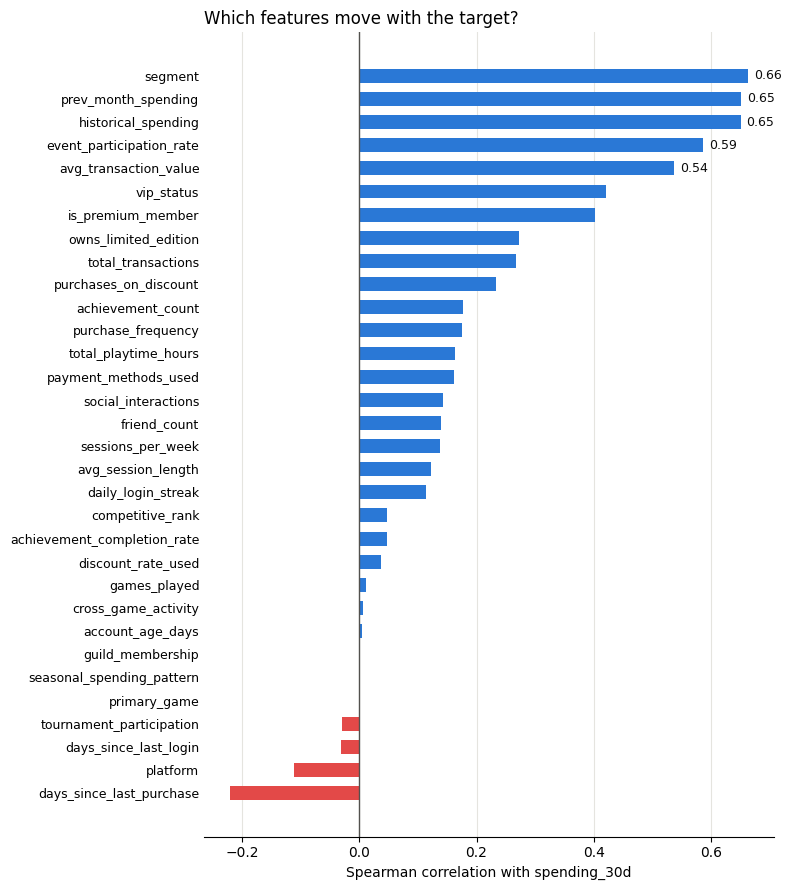

In [11]:
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(r.index, r.values, height=0.6,
        color=['#2a78d6' if v >= 0 else '#e34948' for v in r.values])  # blue = more spend, red = less
ax.axvline(0, color='#52514e', linewidth=1)
for name, v in r.tail(5).items():  # label only the top 5
    ax.text(v + 0.01, name, f"{v:.2f}", va='center', fontsize=9, color='#0b0b0b')

ax.set_xlabel('Spearman correlation with spending_30d')
ax.set_title('Which features move with the target?', loc='left')
ax.grid(axis='x', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=9)
plt.tight_layout()
plt.show()

## Spend history vs a zero target

ดูว่ายอดใช้จ่ายในอดีตบอกได้ไหมว่าใครจะไม่ใช้เงินเลยในเดือนหน้า โดยเทียบคนที่ target = 0 กับ target > 0

In [12]:
spend_cols = ['prev_month_spending', 'historical_spending', 'avg_transaction_value', 'total_transactions']
history = pd.DataFrame({'lowest value': tr[spend_cols].min(), 'share at 0': (tr[spend_cols] == 0).mean()})
display(history.style
        .format({'lowest value': '{:.4f}', 'share at 0': '{:.1%}'})
        .set_caption('Spend features: does anyone have 0?'))

,lowest value,share at 0
prev_month_spending,0.0079,0.0%
historical_spending,0.0259,0.0%
avg_transaction_value,0.0007,0.0%
total_transactions,0.0000,0.9%


**NOTE:**

No one has exactly 0 in `prev_month_spending` (lowest is 0.008 THB). But 48% of target (`spending_30d`) is 0.

In [13]:
medians = tr.groupby(np.where(y == 0, 'target = 0', 'target > 0'))[['prev_month_spending', 'historical_spending']].median()
display(medians.style
        .format('{:,.0f}')
        .set_caption('Median spend history (THB), by next-month target'))

,prev_month_spending,historical_spending
target = 0,303,869
target > 0,"1,094","3,136"


**NOTE:**

The ones that don't spend have less `prev_month_spending` and `historical_spending`.

### Two groups overlap

median บอกแค่ค่ากลางของแต่ละกลุ่ม histogram นี้แสดงยอดเดือนก่อนของทั้งสองกลุ่มทั้งหมด

แกน x เป็น log scale: แต่ละขั้น (10, 100, 1,000, ...) มากกว่าขั้นก่อน 10 เท่า ถ้าไม่ใช้ log คนเกือบทั้งหมดจะไปกองอยู่แท่งแรก เพราะยอดมีตั้งแต่ประมาณ 1 ถึงเกิน 50,000 บาท

- กลุ่ม target = 0 อยู่ทางซ้ายกว่า แต่สองกลุ่มซ้อนกันเยอะช่วงประมาณ 100–2,000 บาท ตรงนี้ดูจากประวัติอย่างเดียวแยกไม่ออก
- ทางขวาของเส้นประ 5,000 เส้นสีส้มแทบแบน ส่วนสีน้ำเงินมีโหนกที่สอง แปลว่าคนใช้เงินเยอะไม่ค่อยหยุดใช้ ตัวเลขดูได้จากกราฟแท่งถัดไป

In [14]:
prev = tr['prev_month_spending']
bins = np.logspace(0, np.log10(prev.max()), 50)  # log bins from 1 THB; spend spans 1 to 50k+
groups = [(y == 0, 'target = 0 (spends nothing)', '#eb6834', 0.95),
          (y > 0, 'target > 0 (spends something)', '#2a78d6', 0.85)]

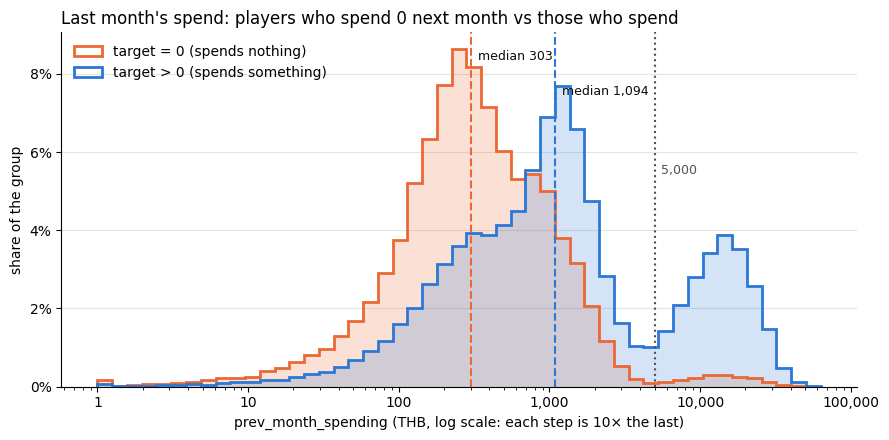

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for mask, label, color, label_y in groups:
    x = prev[mask].clip(lower=1)  # the 0.1% of players below 1 THB go in the first bin
    w = np.full(len(x), 1 / len(x))  # each group sums to 100%, so the two shapes are comparable
    ax.hist(x, bins=bins, weights=w, histtype='stepfilled', alpha=0.2, color=color)
    ax.hist(x, bins=bins, weights=w, histtype='step', linewidth=2, color=color, label=label)
    med = prev[mask].median()
    ax.axvline(med, color=color, linestyle='--', linewidth=1.5)
    ax.text(med * 1.1, label_y, f"median {med:,.0f}", transform=ax.get_xaxis_transform(),
            color='#0b0b0b', fontsize=9, va='top')

ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))  # 1,000 instead of 10^3
ax.axvline(5000, color='#52514e', linestyle=':', linewidth=1.5)
ax.text(5000 * 1.1, 0.6, '5,000', transform=ax.get_xaxis_transform(), fontsize=9, color='#52514e')
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('prev_month_spending (THB, log scale: each step is 10× the last)')
ax.set_ylabel('share of the group')
ax.set_title("Last month's spend: players who spend 0 next month vs those who spend", loc='left')
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### Who drops to 0, by spend band

แบ่งผู้เล่นเป็นช่วงตามยอดใช้จ่ายเดือนก่อน (`prev_month_spending`) แล้วดูว่าแต่ละช่วงมีกี่ % ที่เดือนหน้าไม่ใช้เงินเลย (target = 0)

- คนใช้น้อย (ต่ำกว่า 500 บาท) เดือนหน้าไม่ใช้เงินประมาณ 70%
- ยิ่งยอดสูง สัดส่วนยิ่งลด เกิน 5,000 บาทเหลือแค่ประมาณ 7% (ภาพรวม 48%)

In [16]:
edges = [0, 100, 500, 1000, 2000, 5000, 10000, np.inf]
labels = ['<100', '100–500', '500–1k', '1k–2k', '2k–5k', '5k–10k', '>10k']
band = pd.cut(tr['prev_month_spending'], edges, labels=labels)
zero_by_band = y.groupby(band, observed=True).agg(players='size', zero_share=lambda s: (s == 0).mean())
overall = (y == 0).mean()

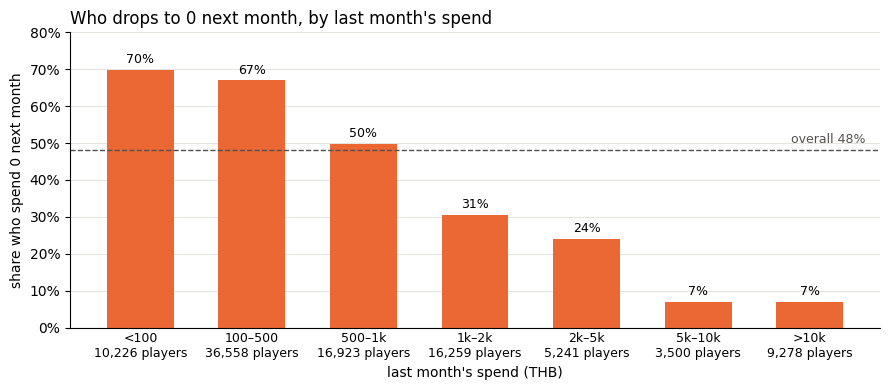

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
ticks = [f"{b}\n{n:,} players" for b, n in zero_by_band['players'].items()]  # band name + group size
bars = ax.bar(ticks, zero_by_band['zero_share'], width=0.6, color='#eb6834')
for bar, share in zip(bars, zero_by_band['zero_share']):
    ax.text(bar.get_x() + bar.get_width() / 2, share + 0.01, f"{share:.0%}", ha='center', va='bottom', fontsize=9)
ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1)
ax.text(len(ticks) - 0.5, overall + 0.01, f"overall {overall:.0%}", ha='right', va='bottom', fontsize=9, color='#52514e')

ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.8)
ax.set_xlabel("last month's spend (THB)")
ax.set_ylabel('share who spend 0 next month')
ax.set_title("Who drops to 0 next month, by last month's spend", loc='left')
ax.tick_params(axis='x', labelsize=9, length=0)
ax.grid(axis='y', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### How much does each feature help on its own?

AUC วัดว่า feature ตัวเดียวแยกคนที่ใช้เงินออกจากคนที่ไม่ใช้ได้ดีแค่ไหน: 0.5 = เดาสุ่ม, 1.0 = แยกได้สมบูรณ์

- ค่าต่ำกว่า 0.5 ก็มีประโยชน์ แค่ทิศกลับกัน เช่น `days_since_last_purchase` ยิ่งนานยิ่งมีโอกาสไม่ใช้เงิน คอลัมน์ `strength` จึงวัดระยะห่างจาก 0.5 ทั้งสองทาง แล้วตารางเรียงตามค่านี้
- ตัด `platform` กับ `primary_game` ออก เพราะเป็นรหัสหมวดหมู่ที่ไม่มีลำดับ ค่า AUC จะขึ้นกับว่าใส่เลขรหัสไว้ยังไง
- `segment` กับ `vip_status` ใช้ได้ เพราะ zero share ลดลงเรื่อยๆ ตามรหัส

In [18]:
unordered = ['platform', 'primary_game']  # category codes with no order: their AUC depends on the numbering
spends = y > 0
auc = {}
for c in feats:
    if c in unordered:
        continue
    m = tr[c].notna()  # roc_auc_score can't take NaN
    auc[c] = roc_auc_score(spends[m], tr.loc[m, c])
auc = pd.Series(auc)

auc_table = pd.DataFrame({
    'AUC': auc,
    'strength': np.maximum(auc, 1 - auc),  # distance from 0.5 in either direction
    'higher value means': np.where(auc >= 0.5, 'more likely to spend', 'more likely to spend 0'),
}).sort_values('strength', ascending=False)

(auc_table.head(10).style
    .format({'AUC': '{:.3f}', 'strength': '{:.3f}'})
    .set_caption('Top 10 features: how well each one alone separates "spends" from "spends 0"'))

,AUC,strength,higher value means
segment,0.756,0.756,more likely to spend
prev_month_spending,0.743,0.743,more likely to spend
historical_spending,0.743,0.743,more likely to spend
event_participation_rate,0.738,0.738,more likely to spend
avg_transaction_value,0.696,0.696,more likely to spend
vip_status,0.654,0.654,more likely to spend
days_since_last_purchase,0.392,0.608,more likely to spend 0
total_transactions,0.599,0.599,more likely to spend
is_premium_member,0.598,0.598,more likely to spend
purchases_on_discount,0.587,0.587,more likely to spend


### This month vs last month

ดูเฉพาะคนที่ใช้เงินทั้งสองเดือน ว่าเดือนนี้ใช้มากกว่าเดือนก่อนกี่เท่า (`target / prev_month_spending`)

วิธีอ่านตาราง: เรียงทุกคนจากอัตราส่วนน้อยไปมาก แล้วดูค่าที่ตำแหน่งต่างๆ เช่น
- **5%:** 5% ของคนมีอัตราส่วนต่ำกว่า 0.97× คือมีแค่ประมาณ 5% ที่ใช้น้อยกว่าเดือนก่อน
- **50% (median):** คนตรงกลางใช้ 2.22× ของเดือนก่อน ครึ่งหนึ่งน้อยกว่านี้ อีกครึ่งมากกว่า
- **25%–75%:** คนครึ่งกลางใช้ระหว่าง 1.53× ถึง 3.55×
- **95%:** มีแค่ 5% ที่ใช้มากกว่า 6.43×

In [19]:
both = (y > 0) & (tr['prev_month_spending'] > 0)
ratio = y[both] / tr.loc[both, 'prev_month_spending']
growth = ratio.quantile([.05, .25, .5, .75, .95]).to_frame('target / prev_month').T
growth.columns = ['5%', '25%', '50% (median)', '75%', '95%']
display(growth.style
        .format('{:.2f}×')
        .set_caption('This month vs last month, for players who spend in both'))

,5%,25%,50% (median),75%,95%
target / prev_month,0.97×,1.53×,2.22×,3.55×,6.43×


### Growth by segment and VIP

อัตราส่วน 2.2× เป็นค่ารวมทุกคน ช่วงกลางกว้างตั้งแต่ 1.5× ถึง 3.6× ตารางนี้ดูว่าอัตราส่วนขึ้นกับ `segment` หรือ `vip_status` ไหม

- ขึ้นชัดมาก: segment 0 ใช้ประมาณ 1.2× ของเดือนก่อน แต่ segment 3 ใช้ประมาณ 4.7× ส่วน VIP tier 0 อยู่ที่ 1.5× และ tier 5 อยู่ที่ 5.9×
- scatter ด้านล่างแสดงทีละ segment (แกน log ทั้งสองแกน) จุดเรียงเป็นเส้นตรงขนานกับเส้น "เท่าเดือนก่อน" แค่ยกสูงขึ้นตาม segment แปลว่าขั้น "ใช้เท่าไร" ของ two-part model ทายได้ดีด้วย `prev_month_spending × อัตราส่วนของ segment/VIP`
- segment 3 มีจุดเรียงแบนอยู่ด้านบนที่ 300,000 คือแถวที่โดนตัดเพดาน

In [20]:
def ratio_quartiles(col):
    value = tr.loc[ratio.index, col].astype('Int64').astype(str).replace('<NA>', 'missing')
    g = ratio.groupby(value)
    t = g.quantile([.25, .5, .75]).unstack()
    t.columns = ['25%', '50% (median)', '75%']
    t.insert(0, 'players', g.size())
    t.index = pd.MultiIndex.from_product([[col], t.index], names=['feature', 'value'])
    return t

growth_by = pd.concat([ratio_quartiles('segment'), ratio_quartiles('vip_status')])
(growth_by.style
    .format({'players': '{:,}', '25%': '{:.2f}×', '50% (median)': '{:.2f}×', '75%': '{:.2f}×'})
    .set_caption('target / prev_month by segment and VIP tier (players who spend in both months)'))

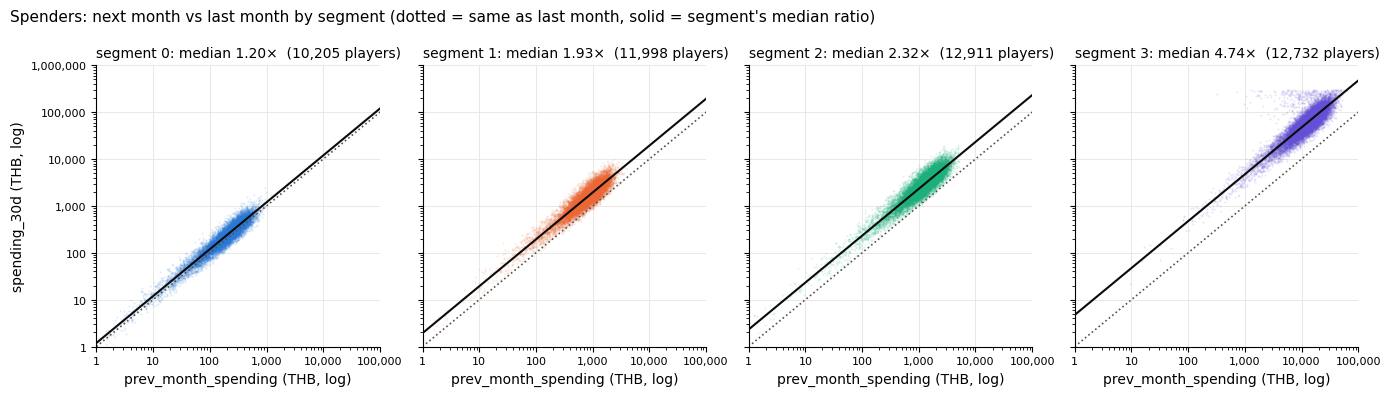

In [21]:
spent = (y > 0) & tr['prev_month_spending'].notna()  # spenders we can plot
seg_colors = {0: '#2a78d6', 1: '#eb6834', 2: '#1baf7a', 3: '#6250d6'}
line = np.array([1, 1e6])

fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
for ax, (s, color) in zip(axes, seg_colors.items()):
    m = spent & (tr['segment'] == s)
    x, t = tr.loc[m, 'prev_month_spending'].clip(lower=1), y[m]
    med = (t / x).median()
    ax.scatter(x, t, s=2, alpha=0.15, color=color, linewidths=0)
    ax.plot(line, line, color='#52514e', linestyle=':', linewidth=1.2)  # same as last month
    ax.plot(line, line * med, color='#0b0b0b', linewidth=1.5)  # this segment's median ratio
    ax.set_title(f"segment {s}: median {med:.2f}×  ({m.sum():,} players)", loc='left', fontsize=10)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1, 1e5)
    ax.set_ylim(1, 1e6)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=8)
    ax.grid(color='#e5e4df', linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.set_xlabel('prev_month_spending (THB, log)')
axes[0].set_ylabel('spending_30d (THB, log)')
fig.suptitle("Spenders: next month vs last month by segment (dotted = same as last month, solid = segment's median ratio)",
             x=0.01, ha='left', fontsize=11)
plt.tight_layout()
plt.show()

## Zero share and median spend per category

ดูว่าแต่ละหมวดมีคนไม่ใช้เงินกี่ % และยอดกลางเท่าไร

- ค่าที่หายไปแยกเป็นกลุ่ม `missing`
- แถบใน `zero_share` เต็มที่ 100%

In [22]:
parts = []
for c in ['vip_status', 'is_premium_member', 'platform', 'games_played']:
    value = tr[c].astype('Int64').astype(str).replace('<NA>', 'missing')  # 0.0 -> '0', NaN -> 'missing'
    t = y.groupby(value).agg(players='size', zero_share=lambda s: (s == 0).mean(), median_spend='median')
    t.index = pd.MultiIndex.from_product([[c], t.index], names=['feature', 'value'])
    parts.append(t)
by_cat = pd.concat(parts)

(by_cat.style
    .format({'players': '{:,}', 'zero_share': '{:.1%}', 'median_spend': '{:,.0f}'})
    .bar(subset='zero_share', color='#86b6ef', vmin=0, vmax=1)  # bar length = share of zero spenders
    .set_caption('Zero share and median spend (THB) per category'))

## The 300,000 cap

ค่าสูงสุดของ target คือ 300,000 บาทพอดี และมีหลายแถวอยู่ที่ค่านี้ เหมือนถูกตัดเพดาน คำถามคือเป็นคนใช้เงินเยอะจริง หรือข้อมูลผิด

In [23]:
capped = tr[y == y.max()]
print(f"{len(capped)} rows at {y.max():,.0f}")
capped[['segment', 'vip_status', 'prev_month_spending', 'historical_spending']].describe().loc[['mean', 'min', 'max']].round(0)

15 rows at 300,000


,segment,vip_status,prev_month_spending,historical_spending
mean,3.0,4.0,40652.0,113431.0
min,3.0,3.0,32260.0,93378.0
max,3.0,5.0,52428.0,161432.0


## Summary

- **Target:** เป็น 0 อยู่ 48%, skew 4.17 คนที่ใช้เกิน 20k มีแค่ 12% ของแถว แต่เป็น 91% ของยอดรวม และเป็นต้นเหตุ 63% ของ error ของ baseline ส่วนแถวที่ target = 0 เป็นต้นเหตุอีก 29%
- **ทิศของ error:** กลุ่ม >20k ตอนพลาดหนักส่วนใหญ่ทายต่ำ (error ทายต่ำ 147M vs ทายสูง 53M) แม้แถวทั่วไปจะทายใกล้ (median ทาย 63k vs จริง 65k) ส่วน error ของกลุ่ม target = 0 (91M) มาจากทายว่าจะใช้เงินทั้งหมด
- **Train vs test:** ไม่มีแถวซ้ำ ไม่มี id ซ้ำ และการกระจายไม่ต่างกัน (KS สูงสุด 0.010) คะแนน CV ในเครื่องน่าจะใกล้กับ Kaggle
- **Missing values:** หายประมาณ 6% ต่อคอลัมน์ และ 85% ของแถวมีค่าหายอย่างน้อยหนึ่งช่อง แต่การหายไม่เกี่ยวกับ target จึงไม่ต้องเพิ่ม flag "is missing"
- **Feature ที่สัมพันธ์กับ target มากสุด (Spearman):** `segment` 0.66, `prev_month_spending` 0.65, `historical_spending` 0.65, `event_participation_rate` 0.59, `avg_transaction_value` 0.54
- **ดูจากประวัติอย่างเดียว ทายยากว่าใครจะเป็น 0:** ไม่มีใครมี `prev_month_spending` เป็น 0 พอดี (ต่ำสุด 0.008 บาท) แต่เดือนหน้า 48% ไม่ใช้เงิน คนกลุ่มนี้มีประวัติต่ำกว่า (median เดือนก่อน 303 vs 1,094) แต่สองกลุ่มซ้อนกันช่วง 100–2,000 บาท คนที่ใช้ต่ำกว่า 500 บาทเดือนหน้าไม่ใช้ประมาณ 70% ส่วนคนที่ใช้เกิน 5,000 บาทมีแค่ประมาณ 7%
- **ใช้เงินหรือไม่ (ดูทีละ feature):** 4 ตัวที่ดีสุดใกล้กันมาก คือ `segment` (AUC 0.756), `prev_month_spending` และ `historical_spending` (0.743), `event_participation_rate` (0.738) ตามด้วย `avg_transaction_value` (0.696) ส่วน `vip_status` (0.654) กับ `is_premium_member` (0.598) อ่อนกว่า ถึง tier สูงๆ ในตารางหมวดจะดูเด่นก็ตาม
- **คนที่ใช้เงินมักใช้มากขึ้น และขึ้นกับ segment:** โดยรวมเดือนนี้ใช้ประมาณ 2.2 เท่าของเดือนก่อน (ครึ่งกลาง 1.5–3.6 เท่า) แต่ segment 0 แค่ 1.2× ส่วน segment 3 ถึง 4.7× และ VIP tier 0 ถึง 5 ไล่จาก 1.5× ถึง 5.9× บนแกน log ยอดเดือนนี้กับเดือนก่อนเรียงเป็นเส้นตรงในแต่ละ segment
- **หมวดหมู่:** `vip_status` มีคนไม่ใช้เงิน 60% ที่ tier 0 ลดเหลือ 8% ที่ tier 5 สมาชิก premium ไม่ใช้เงิน 15% เทียบกับ 54% ของคนที่ไม่ใช่ premium `platform` ก็ต่างกันพอสมควร (platform 0 ไม่ใช้เงิน 41.7% vs platform 1 52.7%) ส่วน `games_played` ไม่มีผล
- **เพดาน 300k:** ทั้ง 15 แถวเป็น segment 3, VIP tier 3–5 และมีประวัติสูง ดูเป็นคนใช้เงินเยอะจริงที่โดนตัดเพดาน ไม่ใช่ข้อมูลผิด

**ลองต่อ:** two-part model คือทายก่อนว่าจะใช้เงินไหม แล้วค่อยทายว่าใช้เท่าไร ส่วนที่ทายว่าใช้เงินไหมต้องรวมหลาย feature เพราะไม่มีตัวไหนแยกได้ดีพอตัวเดียว (AUC สูงสุด 0.76) ส่วนที่ทายว่าใช้เท่าไรใช้ `prev_month_spending` คูณอัตราส่วนตาม `segment`/`vip_status` เป็นจุดเริ่ม

**CAUTION:** Tweedie loss predicts the mean, but this metric is L1-style (sum of absolute errors), which is best when predicting the median. Same issue as combining `p × amount` in a two-part model. Worth trying, but compare it against an MAE-based model on the actual metric.